In [16]:
import pandas as pd
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.preprocessing import LabelEncoder


In [17]:
train = pd.read_csv("sign_mnist_train.csv")
test = pd.read_csv("sign_mnist_test.csv")

In [18]:
x_train = train.iloc[0:, 1:] / 255
x_test = test.iloc[0:, 1:] / 255

encoder = LabelEncoder()
y_train = encoder.fit_transform(train.iloc[0:, 0])
y_test = encoder.transform(test.iloc[0:, 0])

In [20]:
# Create model
model = Sequential([
    keras.layers.Input((784,)),
    Dense(128, activation='relu'),
    Dense(24, activation='softmax')
])


In [21]:
# Compile
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


Epoch 1/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.3404 - loss: 2.2421
Epoch 2/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.5781 - loss: 1.3983
Epoch 3/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6799 - loss: 1.0811
Epoch 4/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7354 - loss: 0.8981
Epoch 5/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7767 - loss: 0.7672
Epoch 6/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8122 - loss: 0.6607
Epoch 7/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8351 - loss: 0.5816
Epoch 8/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8605 - loss: 0.5072
Epoch 9/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8795 - loss: 0.4472
Epoch 10/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8945 - loss: 0.3948
Epoch 11/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9065 - loss: 0.3515
Epoch 12/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step

array([<Axes: >, <Axes: >], dtype=object)

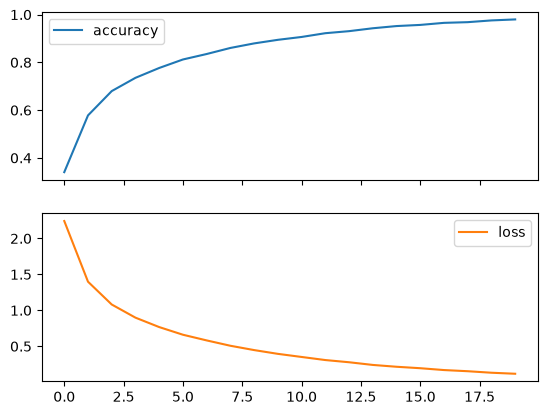

In [22]:
# Train
history = model.fit(x_train, y_train, epochs=20)

# Evaluate
loss, accuracy = model.evaluate(x_test, y_test)
print("Accuracy:", accuracy * 100, "%")

# Plot
pd.DataFrame(history.history).plot(subplots=True)

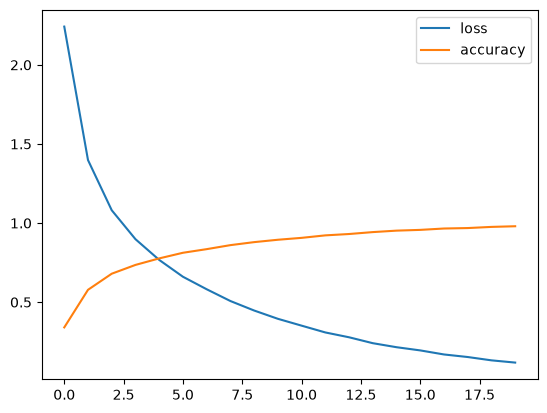

In [25]:
import matplotlib.pyplot as plt
for k in ['loss', 'accuracy']: plt.plot(history.history[k], label=k)
plt.legend(); plt.show()